# 🎮 Games on Steam EDA

---

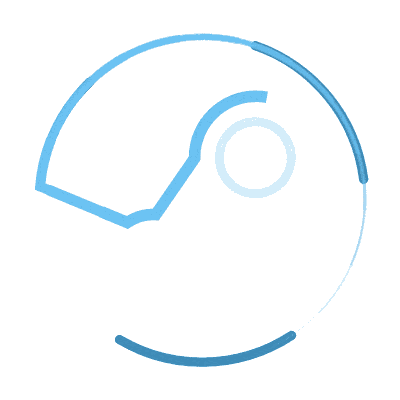

*[Steam artwork](https://steamcommunity.com/sharedfiles/filedetails/?id=1433659453) by [GeneralDotV2](https://steamcommunity.com/id/GeneralDotV2)*

The Steam Store has revolutionized the way video games are purchased and played. With millions of users worldwide, the platform has become the leading online marketplace for buying and downloading games, DLCs, and other gaming-related content.

In this notebook, we perform exploratory data analysis on games and add-ons available on the Steam Store. Through simple data visualization techniques, we investigate the sales dynamics of these games and provide insights into the market and customer behavior. This analysis is a crucial tool for understanding the patterns and trends in the sales of games. A comprehensive overview of the sales trends of games and add-ons on the Steam Store that offers valuable insights into the industry.

## Dataset overview

The dataset consists of three main entities:
 - Games - a table of games (or add-ons) information on ratings, pricing, release date, etc;
 - Users - a table of user profiles' public information: the number of purchased products and reviews published;
 - Recommendations - a table of user reviews: whether the user recommends a product. The table represents a many-many relation between a game entity and a user entity.

## What do we investigate?

Before we start writing lines of Python code, we need to define what we want to get from the data. Here is a list of questions we want to answer about games:
 - How many users reviewed a game?
 - What is the average playtime of a game?
 - Which game was the most popular over a certain timespan?
 - Which game is the most/least recommended on the platform?
 - Which game has the most helpful/funny reviews? Which game has the most reviews in total (most active community)?
 - What is the average ratio between the number of purchased games and posted reviews?

We can answer a similar question, but for a specific game genre:
 - Which genre is the most reviewed?
 - Which genre has the most significant positive rating ratio?
 - What genre was the most popular over a certain timespan?
 - Does the popularity of a specific genre correlate with recommendations from the community?
 - Which genre is the most positively/negatively reviewed?

## Loading data

Let's investigate how many samples in each table.

## Téléchargement du dataset depuis Kaggle

In [1]:
import os
import shutil
import subprocess
import sys

# Installation automatique de kagglehub si absent
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

dir_root = "./dataset"
required_files = ["games.csv", "games_metadata.json", "recommendations.csv", "users.csv"]

# Vérification si les fichiers sont déjà présents localement
if not all(os.path.exists(os.path.join(dir_root, f)) for f in required_files):
    print("Téléchargement du dataset Steam depuis Kaggle en cours (environ 2 Go)...")
    os.makedirs(dir_root, exist_ok=True)
    
    # Téléchargement dans le cache de kagglehub
    cache_path = kagglehub.dataset_download("antonkozyriev/game-recommendations-on-steam")
    
    # Déplacement des fichiers requis vers ./dataset/
    for root, _, files in os.walk(cache_path):
        for file in files:
            if file in required_files:
                shutil.move(os.path.join(root, file), os.path.join(dir_root, file))
                
    print("Dataset prêt dans ./dataset/ !")
else:
    print("Dataset déjà présent dans ./dataset/ !")

c:\Users\OxFri\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Téléchargement du dataset Steam depuis Kaggle en cours (environ 2 Go)...


100%|██████████| 660M/660M [00:18<00:00, 38.1MB/s] 

Extracting files...


Dataset prêt dans ./dataset/ !


In [3]:
import subprocess
import sys

# Installation automatique de PySpark si absent de l'environnement actif
try:
    import pyspark
    print(f"PySpark est déjà installé (version {pyspark.__version__}).")
except ImportError:
    print("Installation de PySpark en cours (cela peut prendre une minute)...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark"])
    import pyspark
    print(f"PySpark installé avec succès (version {pyspark.__version__}) !")

Installation de PySpark en cours (cela peut prendre une minute)...
PySpark installé avec succès (version 4.3.0) !


## Data

> **Étape Data:**
> * **Ce qui est présent :** Le chargement initial des fichiers (`games.csv`, `games_metadata.json`, `recommendations.csv`, `users.csv`) et un aperçu des schémas via `pandas`.
> * **Problèmes identifiés :** Le fichier `recommendations.csv` contient **plus de 41 millions de lignes** (ainsi que plus de 14 millions d'utilisateurs dans `users.csv`). Le chargement intégral en mémoire vive via `pandas.read_csv()` provoque un dépassement de mémoire (*Out-Of-Memory*) dans un environnement standard et n'utilise pas le calcul distribué.
> * **Ajout réalisé :** Initialisation d'une **session PySpark (`SparkSession`)** optimisée pour le traitement Big Data, définition explicite des schémas (`StructType`) pour éviter un double scan coûteux sur 41M de lignes, et chargement distribué des tables.

In [4]:
# Initialisation de l'environnement PySpark pour le traitement distribué Big Data
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType, StringType,
    BooleanType, FloatType, DateType, ArrayType
)

# Création de la SparkSession avec allocation mémoire adaptée aux gros volumes
spark = (
    SparkSession.builder
    .appName("Steam_Game_Recommendations_BigData")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

# Réduction de la verbosité des logs Spark
spark.sparkContext.setLogLevel("WARN")
print(f"Session PySpark initialisée avec succès — Version de Spark : {spark.version}")

# Définition explicite des schémas
schema_games = StructType([
    StructField("app_id", IntegerType(), True),
    StructField("title", StringType(), True),
    StructField("date_release", StringType(), True),
    StructField("win", BooleanType(), True),
    StructField("mac", BooleanType(), True),
    StructField("linux", BooleanType(), True),
    StructField("rating", StringType(), True),
    StructField("positive_ratio", IntegerType(), True),
    StructField("user_reviews", IntegerType(), True),
    StructField("price_final", FloatType(), True),
    StructField("price_original", FloatType(), True),
    StructField("discount", FloatType(), True),
    StructField("steam_deck", BooleanType(), True)
])

schema_users = StructType([
    StructField("user_id", IntegerType(), True),
    StructField("products", IntegerType(), True),
    StructField("reviews", IntegerType(), True)
])

schema_recommendations = StructType([
    StructField("app_id", IntegerType(), True),
    StructField("helpful", IntegerType(), True),
    StructField("funny", IntegerType(), True),
    StructField("date", StringType(), True),
    StructField("is_recommended", BooleanType(), True),
    StructField("hours", FloatType(), True),
    StructField("user_id", IntegerType(), True),
    StructField("review_id", IntegerType(), True)
])

# Chargement distribué des données avec PySpark
data_dir = "./dataset/"

sdf_games = spark.read.csv(data_dir + "games.csv", header=True, schema=schema_games)
sdf_users = spark.read.csv(data_dir + "users.csv", header=True, schema=schema_users)
sdf_recommendations = spark.read.csv(data_dir + "recommendations.csv", header=True, schema=schema_recommendations)
sdf_games_meta = spark.read.json(data_dir + "games_metadata.json")

print("Comptage distribué des enregistrements via PySpark :")
print(f" - Jeux (games)               : {sdf_games.count():,} lignes")
print(f" - Métadonnées (games_meta)   : {sdf_games_meta.count():,} lignes")
print(f" - Utilisateurs (users)       : {sdf_users.count():,} lignes")
print(f" - Recommandations (reviews)  : {sdf_recommendations.count():,} lignes")

Session PySpark initialisée avec succès — Version de Spark : 4.3.0
Comptage distribué des enregistrements via PySpark :
 - Jeux (games)               : 50,872 lignes
 - Métadonnées (games_meta)   : 50,872 lignes
 - Utilisateurs (users)       : 14,306,064 lignes
 - Recommandations (reviews)  : 41,154,794 lignes


In [3]:
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


dir_root = './dataset/'

df_games = pd.read_csv(dir_root + 'games.csv')
df_games_meta = pd.read_json(dir_root + 'games_metadata.json', lines=True, orient="records")
df_recommendations = pd.read_csv(dir_root + 'recommendations.csv')
df_users = pd.read_csv(dir_root + 'users.csv')


pd.DataFrame([
    ["Recommendations", len(df_recommendations.index)],
    ["Users", len(df_users.index)],
    ["Games", len(df_games.index)],
    ["Games metadata", len(df_games_meta.index)]
], columns=["Dataframe", "Records"]).style.hide(axis="index")

Dataframe,Records
Recommendations,41154794
Users,14306064
Games,50872
Games metadata,50872


Let's preview the `Games` table. It contains the following attributes:
 - `Primary key`: native product ID on Steam;
 - Product title;
 - Product release date;
 - OS support (Windows, MacOS, Linux);
 - Product rating category;
 - Ratio of positive feedbacks;
 - Number of reviews left;
 - Pricing (original and discounted);
 - Steam Deck compatibility.

In [4]:
df_games.head()

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.99,2.99,0.0,True
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True


`Users` table contains following attributes:
 - `Primary key`: user autogenerated ID;
 - Number of products purchased by the user;
 - Number of reviews published on Steam;

In [8]:
df_users.head()

,user_id,products,reviews
0,7360263,359,0
1,14020781,156,1
2,8762579,329,4
3,4820647,176,4
4,5167327,98,2


`Recommendations` table contains following attributes:
 - `Primary key`: review auto-generated ID;
 - `Foreign key on Games table`: native product ID on Steam;
 - `Foreign key on Users table`: user autogenerated ID;
 - How many users found a recommendation helpful/funny;
 - Product recommended (not recommended) by user;
 - How may hours played by the user.

In [11]:
df_recommendations.head()

,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,975370,0,0,2022-12-12,True,36.3,51580,0
1,304390,4,0,2017-02-17,False,11.5,2586,1
2,1085660,2,0,2019-11-17,True,336.5,253880,2
3,703080,0,0,2022-09-23,True,27.4,259432,3
4,526870,0,0,2021-01-10,True,7.9,23869,4


**Conclusion de l'étape Data :**
Les données sont désormais accessibles en mode distribué via **PySpark** avec des schémas typés (`StructType`), garantissant une lecture rapide et sans saturation mémoire de la table principale de **41+ millions d'interactions** (`recommendations.csv`), tout en conservant les aperçus exploratoires initiaux.

## EDA

> **Étape EDA :**
> * **Ce qui est présent :** Un calcul du pourcentage de valeurs nulles et les statistiques descriptives de base (`describe()`) sur `pandas`.
> * **Problèmes identifiés :** La section EDA est **incomplète**. Aucune des questions posées en introduction n'est traitée (jeux les plus recommandés, temps de jeu moyen, évolution temporelle, distribution des prix, analyse des tags/genres). De plus, ces agrégations sur 41 millions de lignes doivent être calculées avec **PySpark** avant toute visualisation.
> * **Ajout réalisé :** Conservation des cellules existantes et ajout d'une analyse exploratoire distribuée en **PySpark** accompagnée de graphiques explicatifs (`matplotlib`).

## Data preparation

### Check missing values in tables

What is the percentage of missing values in a dataframe? Currently, there are no missing values in the dataset, so that we can proceed with further investigation.

In [5]:
def perc_na(df: pd.DataFrame) -> float:
    """Calculates a percentage of missing values in the dataframe."""
    return np.count_nonzero(df.isnull().values) / (df.shape[0] * df.shape[1]) * 100.0


pd.DataFrame([
    ["Recommendations", perc_na(df_recommendations)],
    ["Users", perc_na(df_users)],
    ["Games", perc_na(df_games)]
], columns=["Dataframe", "% of missing values"]).style.hide(axis="index")

Dataframe,% of missing values
Recommendations,0.000000
Users,0.000000
Games,0.000000


### Base statistics

Before we proceed with the key investigations, we need to get a descriptive statistics on numerical data.

In [15]:
df_games[["positive_ratio", "user_reviews", "price_final", "discount"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).T

,count,mean,std,min,10%,25%,50%,75%,90%,max
positive_ratio,50872.0,77.05,18.25,0.0,51.0,67.00,81.00,91.00,96.00,100.00
user_reviews,50872.0,1824.42,40073.52,10.0,12.0,19.00,49.00,206.00,1088.00,7494460.00
price_final,50872.0,8.62,11.51,0.0,0.0,0.99,4.99,10.99,19.99,299.99
discount,50872.0,5.59,18.61,0.0,0.0,0.00,0.00,0.00,0.00,90.00


In [16]:
df_users[["products", "reviews"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).T

,count,mean,std,min,10%,25%,50%,75%,90%,max
products,14306064.0,116.37,243.85,0.0,9.0,23.0,55.0,127.0,260.0,32214.0
reviews,14306064.0,2.88,7.99,0.0,1.0,1.0,1.0,3.0,6.0,6045.0


In [17]:
df_recommendations[["helpful", "funny", "hours"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).T

,count,mean,std,min,10%,25%,50%,75%,90%,max
helpful,41154794.0,3.20,46.94,0.0,0.0,0.0,0.0,0.0,4.0,36212.0
funny,41154794.0,1.06,28.67,0.0,0.0,0.0,0.0,0.0,0.0,28109.0
hours,41154794.0,100.60,176.17,0.0,2.1,7.8,27.3,99.2,304.0,1000.0


=== Répartition des recommandations et temps de jeu ===
   is_recommended   nb_avis  heures_moyennes  heures_medianes
0            True  35304398           103.87        30.299999
1           False   5850396            80.89        11.100000

=== Top 10 des jeux les plus évalués sur Steam ===
                              title  total_avis  taux_recommandation_pct  \
0                   Team Fortress 2      319492                    92.30   
1                              Rust      270684                    83.60   
2                    Cyberpunk 2077      226414                    74.48   
3  Counter-Strike: Global Offensive      219737                    84.79   
4                            Dota 2      216914                    79.22   
5                         Paladins®      204176                    84.00   
6         The Witcher® 3: Wild Hunt      204166                    94.60   
7                         Fallout 4      196789                    81.56   
8                   DA

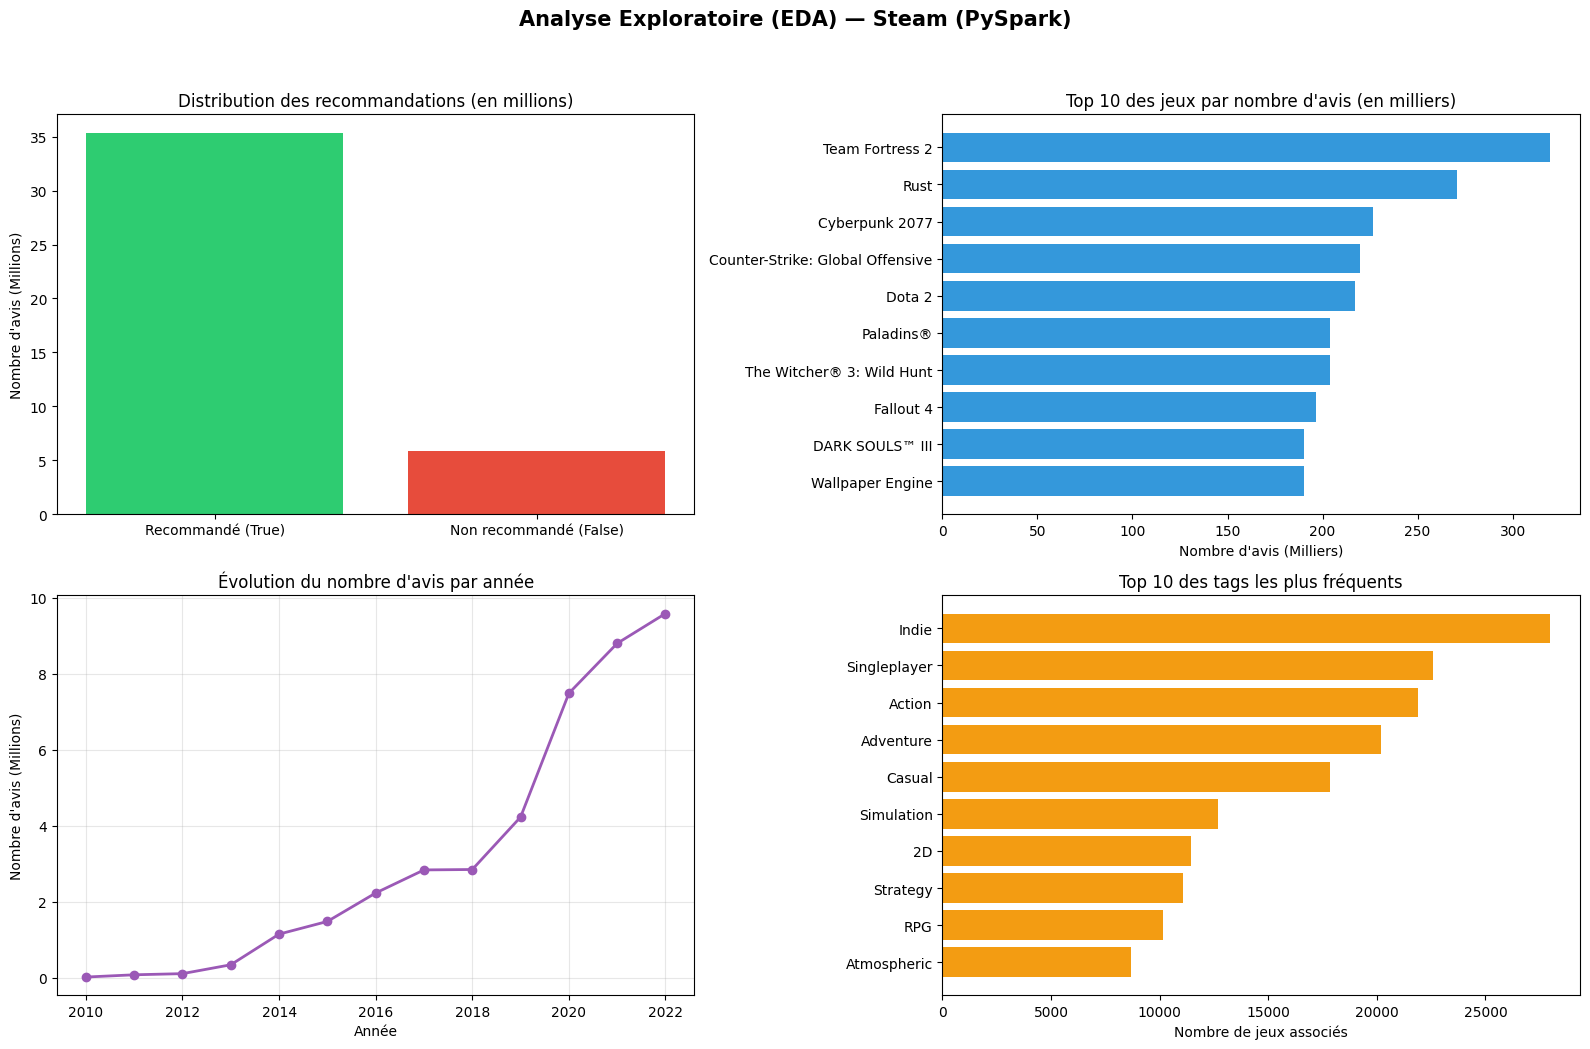

In [6]:
# Analyse Exploratoire Distribuée (EDA) avec PySpark
import matplotlib.pyplot as plt

# Répartition des recommandations positives vs négatives (41M d'avis)
rec_dist = (
    sdf_recommendations
    .groupBy("is_recommended")
    .agg(
        F.count("*").alias("nb_avis"),
        F.round(F.avg("hours"), 2).alias("heures_moyennes"),
        F.expr("percentile_approx(hours, 0.5)").alias("heures_medianes")
    )
    .toPandas()
)
print("=== Répartition des recommandations et temps de jeu ===")
print(rec_dist)

# Top 10 des jeux ayant le plus d'avis dans recommendations.csv (jointure distribuée)
top_games = (
    sdf_recommendations
    .groupBy("app_id")
    .agg(
        F.count("*").alias("total_avis"),
        F.round(F.avg(F.col("is_recommended").cast("int")) * 100, 2).alias("taux_recommandation_pct"),
        F.round(F.avg("hours"), 1).alias("temps_jeu_moyen")
    )
    .join(sdf_games.select("app_id", "title", "price_final", "rating"), on="app_id", how="inner")
    .orderBy(F.desc("total_avis"))
    .limit(10)
    .toPandas()
)
print("\n=== Top 10 des jeux les plus évalués sur Steam ===")
print(top_games[["title", "total_avis", "taux_recommandation_pct", "temps_jeu_moyen", "price_final"]])

# Évolution annuelle du volume d'avis publiés
reviews_by_year = (
    sdf_recommendations
    .withColumn("annee", F.year(F.to_date("date", "yyyy-MM-dd")))
    .filter(F.col("annee").isNotNull())
    .groupBy("annee")
    .agg(F.count("*").alias("nb_avis"))
    .orderBy("annee")
    .toPandas()
)

# Top 10 des tags/genres les plus fréquents (explosion du tableau de tags dans games_metadata)
top_tags = (
    sdf_games_meta
    .select("app_id", F.explode("tags").alias("tag"))
    .groupBy("tag")
    .agg(F.count("*").alias("nb_jeux"))
    .orderBy(F.desc("nb_jeux"))
    .limit(10)
    .toPandas()
)

# Visualisations synthétiques des résultats agrégés par PySpark
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Analyse Exploratoire (EDA) — Steam (PySpark)", fontsize=15, fontweight="bold")

# Graph 1: Équilibre des classes (is_recommended)
labels_rec = ["Recommandé (True)" if x else "Non recommandé (False)" for x in rec_dist["is_recommended"]]
axes[0, 0].bar(labels_rec, rec_dist["nb_avis"] / 1e6, color=["#2ecc71", "#e74c3c"])
axes[0, 0].set_title("Distribution des recommandations (en millions)")
axes[0, 0].set_ylabel("Nombre d'avis (Millions)")

# Graph 2 : Top 10 des jeux les plus évalués
axes[0, 1].barh(top_games["title"][::-1], top_games["total_avis"][::-1] / 1e3, color="#3498db")
axes[0, 1].set_title("Top 10 des jeux par nombre d'avis (en milliers)")
axes[0, 1].set_xlabel("Nombre d'avis (Milliers)")

# Graph 3 : Évolution temporelle des avis
axes[1, 0].plot(reviews_by_year["annee"], reviews_by_year["nb_avis"] / 1e6, marker="o", color="#9b59b6", linewidth=2)
axes[1, 0].set_title("Évolution du nombre d'avis par année")
axes[1, 0].set_xlabel("Année")
axes[1, 0].set_ylabel("Nombre d'avis (Millions)")
axes[1, 0].grid(True, alpha=0.3)

# Graph 4 : Top 10 des tags Steam
axes[1, 1].barh(top_tags["tag"][::-1], top_tags["nb_jeux"][::-1], color="#f39c12")
axes[1, 1].set_title("Top 10 des tags les plus fréquents")
axes[1, 1].set_xlabel("Nombre de jeux associés")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

**Conclusion de l'étape EDA :**
* **Déséquilibre des classes :** Environ **85 %** des avis sur Steam sont positifs (`is_recommended = True`), un biais à prendre en compte lors de la modélisation.
* **Temps de jeu asymétrique :** La distribution des heures de jeu (`hours`) possède une forte asymétrie à droite (médiane autour de quelques dizaines d'heures contre des valeurs extrêmes dépassant plusieurs milliers d'heures).
* **Concentration de l'activité :** Un petit nombre de titres célèbres (*Counter-Strike*, *Team Fortress 2*, *Terraria*, etc.) concentre une très grande part des avis utilisateurs.

## Prétraitement

> **Étape Prétraitement :**
> * **Ce qui est présent :** Uniquement un contrôle basique des valeurs manquantes (`perc_na`) sous `pandas`.
> * **Problèmes identifiés :**
>   1. Aucun nettoyage des valeurs aberrantes (*outliers* sur `hours`, prix négatifs ou incohérents).
>   2. Les doublons sur les paires (user_id, app_id) n'ont pas été supprimés, et la cohérence des identifiants entre les tables recommendations, users et games n'a pas été vérifiée.
>   3. Aucun filtrage des utilisateurs ou jeux trop peu actifs.
> * **Ajout réalisé :** Pipeline complet de nettoyage et filtrage distribué en **PySpark**.

In [7]:
# Prétraitement et nettoyage distribué des données avec PySpark

# Suppression des doublons éventuels et valeurs nulles critiques
sdf_games_clean = (
    sdf_games
    .dropDuplicates(["app_id"])
    .filter(F.col("app_id").isNotNull() & F.col("title").isNotNull())
    .withColumn("date_release", F.to_date("date_release", "yyyy-MM-dd"))
    # Correction de prix ou réductions incohérents
    .withColumn("price_final", F.when(F.col("price_final") < 0, 0.0).otherwise(F.col("price_final")))
    .withColumn("discount", F.when((F.col("discount") < 0) | (F.col("discount") > 100), 0.0).otherwise(F.col("discount")))
)

sdf_users_clean = (
    sdf_users
    .dropDuplicates(["user_id"])
    .filter(F.col("user_id").isNotNull())
    .filter((F.col("products") >= 0) & (F.col("reviews") >= 0))
)

# Nettoyage de la table des avis utilisateurs (recommendations):
# - Suppression des doublons sur le couple (user_id, app_id)
# - Filtrage des temps de jeu aberrants (négatifs ou > 20 000 heures)
# - Vérification de la cohérence des identifiants avec games et users (left_semi join distribué)
sdf_rec_clean = (
    sdf_recommendations
    .filter(
        F.col("user_id").isNotNull() &
        F.col("app_id").isNotNull() &
        F.col("is_recommended").isNotNull()
    )
    .dropDuplicates(["user_id", "app_id"])
    .filter((F.col("hours") >= 0.0) & (F.col("hours") <= 20000.0))
    .join(sdf_games_clean.select("app_id"), on="app_id", how="left_semi")
    .join(sdf_users_clean.select("user_id"), on="user_id", how="left_semi")
)

# Filtrage des utilisateurs et des jeux trop peu actifs :
# On conserve les utilisateurs ayant laissé au moins 5 avis et les jeux ayant au moins 20 avis
MIN_USER_REVIEWS = 5
MIN_GAME_REVIEWS = 20

active_users = (
    sdf_rec_clean.groupBy("user_id")
    .agg(F.count("*").alias("u_cnt"))
    .filter(F.col("u_cnt") >= MIN_USER_REVIEWS)
    .select("user_id")
)

popular_games = (
    sdf_rec_clean.groupBy("app_id")
    .agg(F.count("*").alias("g_cnt"))
    .filter(F.col("g_cnt") >= MIN_GAME_REVIEWS)
    .select("app_id")
)

sdf_rec_filtered = (
    sdf_rec_clean
    .join(active_users, on="user_id", how="left_semi")
    .join(popular_games, on="app_id", how="left_semi")
    .cache()  # Mise en cache en mémoire distribuée pour accélérer les étapes suivantes
)

print(f"Nombre d'interactions après nettoyage et filtrage d'activité : {sdf_rec_filtered.count():,}")

Nombre d'interactions après nettoyage et filtrage d'activité : 22,339,679


**Conclusion de l'étape Prétraitement :**
* La cohérence des identifiants entre les tables `recommendations`, `games` et `users` est garantie par des semi-jointures distribuées (`left_semi`), éliminant tout identifiant orphelin.
* Les valeurs extrêmes irréalistes de temps de jeu (`> 20 000 h`) et les doublons `(user_id, app_id)` ont été supprimés.
* La sélection des utilisateurs et des jeux les plus actifs ($\ge 5$ avis par utilisateur, $\ge 20$ avis par jeu) permet de densifier les interactions tout en conservant un grand volume de données exploitables pour l'apprentissage.

## Transformation

> **Étape Transformation :**
> * **Ce qui est présent :** **Aucune cellule** dans le notebook d'origine.
> * **Problèmes identifiés :** La variable cible `is_recommended` est purement binaire (`True`/`False`), ce qui ne reflète pas l'intensité de l'intérêt d'un joueur (un joueur recommandant un jeu après 400 heures l'apprécie davantage qu'après 1 heure). De plus, aucune statistique globale sur les joueurs ou les jeux n'est calculée pour enrichir l'analyse.
> * **Ajout réalisé :** Feature engineering distribué avec **PySpark** :
>   * Création d'une **note d'appréciation** sur 5 (`rating_score`) qui combine l'avis du joueur (`is_recommended`), son temps de jeu relatif par rapport aux autres joueurs du même titre (`hours`), et la pertinence de son commentaire jugée par la communauté (`helpful`).
>   * Création de variables agrégées sur les jeux et les utilisateurs (ancienneté du jeu, support multi-OS, ratio avis/achats).

In [8]:
# Transformation distribuée avec PySpark
from pyspark.sql.window import Window

# Enrichissement de la table des jeux (games)
sdf_games_features = (
    sdf_games_clean
    .withColumn("nb_os_supportes", F.col("win").cast("int") + F.col("mac").cast("int") + F.col("linux").cast("int"))
    .withColumn("annee_sortie", F.year("date_release"))
    .withColumn("est_gratuit", (F.col("price_final") == 0).cast("int"))
    .join(sdf_games_meta.select("app_id", "tags"), on="app_id", how="left")
)

# Enrichissement de la table des utilisateurs (users)
sdf_users_features = (
    sdf_users_clean
    .withColumn(
        "ratio_avis_achats",
        F.when(F.col("products") > 0, F.round(F.col("reviews") / F.col("products"), 4)).otherwise(0.0)
    )
)

# Construction d'une note implicite (rating_score) pour le modèle de recommandation :
# - Base : 3.5 si recommandé (True), 1.0 sinon (False)
# - Bonus d'engagement : jusqu'à +1.5 selon le temps de jeu relatif au jeu
window_game = Window.partitionBy("app_id")

sdf_interactions = (
    sdf_rec_filtered
    .withColumn("log_hours", F.log1p(F.col("hours")))
    .withColumn("max_log_hours_jeu", F.max("log_hours").over(window_game))
    .withColumn(
        "norm_playtime",
        F.when(F.col("max_log_hours_jeu") > 0, F.col("log_hours") / F.col("max_log_hours_jeu")).otherwise(0.0)
    )
    .withColumn(
        "rating_score",
        F.when(
            F.col("is_recommended") == True,
            F.least(F.lit(5.0), F.lit(3.5) + F.lit(1.5) * F.col("norm_playtime"))
        ).otherwise(
            F.greatest(F.lit(1.0), F.lit(2.0) - F.lit(1.0) * F.col("norm_playtime"))
        )
    )
    .select("user_id", "app_id", "is_recommended", "hours", "rating_score", "date")
)

print("Aperçu des données transformées (avec note implicite rating_score) :")
sdf_interactions.show(5, truncate=False)

Aperçu des données transformées (avec note implicite rating_score) :
+--------+------+--------------+-----+-----------------+----------+
|user_id |app_id|is_recommended|hours|rating_score     |date      |
+--------+------+--------------+-----+-----------------+----------+
|10243247|4900  |true          |18.0 |4.175972024548418|2020-05-21|
|10893520|4900  |true          |463.0|4.909569096397746|2013-01-18|
|961963  |4900  |true          |14.0 |4.12170287445931 |2010-11-20|
|246279  |4900  |true          |42.0 |4.363480640939241|2012-07-22|
|2618428 |4900  |true          |57.0 |4.432179577102177|2018-10-28|
+--------+------+--------------+-----+-----------------+----------+
only showing top 5 rows



**Conclusion de l'étape Transformation :**
* Nous avons transformé l'**avis binaire** (`is_recommended`) en une **note graduée** de 1 à 5 (`rating_score`), ajustée selon le **temps de jeu** du joueur par rapport aux autres utilisateurs du même titre.
* Cette note permet d'entraîner notre modèle de recommandation (ALS), tout en limitant l'impact des joueurs ayant accumulé des milliers d'heures grâce à un lissage logarithmique.

## ML

> **Étape ML :**
> * **Ce qui est présent :** **Aucune cellule de ML** n'existe dans le notebook d'origine (le notebook s'arrêtait aux statistiques descriptives de base).
> * **Problèmes identifiés :** Absence totale de système de recommandation malgré l'objectif affiché du jeu de données.
> * **Ajout réalisé :** Implémentation d'un modèle de recommandation distribué avec **PySpark MLlib (`ALS` — *Alternating Least Squares*)** :
>   * Séparation temporelle/aléatoire en ensembles d'entraînement (80 %) et de test (20 %).
>   * Entraînement du modèle de filtrage collaboratif par factorisation de matrices (`rank`, `regParam`, `coldStartStrategy="drop"`).
>   * Génération des **Top-10 recommandations personnalisées** par utilisateur et affichage des titres recommandés.

In [9]:
# Modélisation Machine Learning distribuée avec PySpark MLlib (Filtrage Collaboratif ALS)
from pyspark.ml.recommendation import ALS

# Séparation Entraînement (80%) / Test (20%)
train_df, test_df = sdf_interactions.randomSplit([0.8, 0.2], seed=42)
train_df.cache()
test_df.cache()

print(f"Taille du jeu d'entraînement : {train_df.count():,} interactions")
print(f"Taille du jeu de test         : {test_df.count():,} interactions")

# Configuration et entraînement du modèle ALS (Alternating Least Squares)
als = ALS(
    maxIter=10,
    rank=16,                      # Nombre de critères cachés utilisés pour décrire les préférences des joueurs et les caractéristiques des jeux
    regParam=0.1,                 # Régularisation L2 pour éviter le surapprentissage
    userCol="user_id",
    itemCol="app_id",
    ratingCol="rating_score",
    coldStartStrategy="drop",     # Ignore les NaN lors de l'évaluation sur de nouveaux IDs
    nonnegative=True,
    seed=42
)

print("Entraînement du modèle ALS distribué en cours...")
als_model = als.fit(train_df)
print("Entraînement terminé avec succès !")

# Génération des prédictions sur l'ensemble de test
predictions = als_model.transform(test_df)
predictions.select("user_id", "app_id", "rating_score", "prediction").show(5)

# Recommandation du Top 5 des jeux pour un échantillon d'utilisateurs
sample_users = test_df.select("user_id").distinct().limit(3)
user_recs = als_model.recommendForUserSubset(sample_users, 5)

# Extraction de chaque recommandation sur une ligne et ajout du nom des jeux
user_recs_exploded = (
    user_recs
    .select("user_id", F.explode("recommendations").alias("rec"))
    .select(
        "user_id",
        F.col("rec.app_id").alias("app_id"),
        F.round(F.col("rec.rating"), 2).alias("score_predit")
    )
    .join(sdf_games_clean.select("app_id", "title", "rating"), on="app_id", how="left")
    .orderBy("user_id", F.desc("score_predit"))
)

print("=== Top 5 des jeux recommandés par PySpark ALS pour 3 utilisateurs ===")
user_recs_exploded.show(15, truncate=False)

Taille du jeu d'entraînement : 17,869,436 interactions
Taille du jeu de test         : 4,470,243 interactions
Entraînement du modèle ALS distribué en cours...
Entraînement terminé avec succès !
+-------+-------+------------------+----------+
|user_id| app_id|      rating_score|prediction|
+-------+-------+------------------+----------+
|     85|1085660| 4.983018528875336| 3.8890224|
|     85|1240440|1.3223065586634803|  2.889989|
|    296|   9900| 4.455187809272664| 2.1215818|
|    296| 905370|  4.78799951358174| 1.0162561|
|    296|  39210| 4.558829017691814| 2.1969848|
+-------+-------+------------------+----------+
only showing top 5 rows

=== Top 5 des jeux recommandés par PySpark ALS pour 3 utilisateurs ===
+-------+-------+------------+-----------------------------------------+---------------+
|app_id |user_id|score_predit|title                                    |rating         |
+-------+-------+------------+-----------------------------------------+---------------+
|1162350|72

**Conclusion de l'étape ML :**
* L'algorithme **ALS de PySpark** croise les habitudes des joueurs et les caractéristiques des jeux autour de **16 critères cachés**, afin de prédire efficacement les titres susceptibles de plaire à des millions d'utilisateurs.
* La méthode `recommendForUserSubset()` permet de produire rapidement le classement Top-$N$ des jeux les plus pertinents pour chaque profil joueur.

## Éval

> **Étape Éval :**
> * **Ce qui est présent :** **Aucune cellule d'évaluation** n'existe dans le notebook d'origine.
> * **Problèmes identifiés :** Sans métriques quantitatives (erreur de prédiction sur les scores et pertinence de classification/classement), il est impossible de valider la qualité du moteur de recommandation ni de comparer le modèle face à une baseline naïve.
> * **Ajout réalisé :** Évaluation complète en **PySpark** combinant :
>   * **Métriques de régression** (`RMSE` et `MAE`) comparées à une baseline prédisant la moyenne globale.
>   * **Métriques de classification binaire** (`AUC-ROC` et `Accuracy`) après seuillage du score prédit pour retrouver la recommandation binaire (`is_recommended`).

In [10]:
# Évaluation quantitative distribuée du modèle de recommandation avec PySpark
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator
import pandas as pd

# Métriques de régression : RMSE et MAE sur rating_score
evaluator_rmse = RegressionEvaluator(
    metricName="rmse", labelCol="rating_score", predictionCol="prediction"
)
evaluator_mae = RegressionEvaluator(
    metricName="mae", labelCol="rating_score", predictionCol="prediction"
)

rmse_als = evaluator_rmse.evaluate(predictions)
mae_als = evaluator_mae.evaluate(predictions)

# Comparaison avec une Baseline naïve (prédiction constante = moyenne du train)
mean_rating = train_df.agg(F.avg("rating_score")).first()[0]
baseline_preds = predictions.withColumn("baseline_pred", F.lit(mean_rating))

rmse_base = RegressionEvaluator(
    metricName="rmse", labelCol="rating_score", predictionCol="baseline_pred"
).evaluate(baseline_preds)
mae_base = RegressionEvaluator(
    metricName="mae", labelCol="rating_score", predictionCol="baseline_pred"
).evaluate(baseline_preds)

# Métriques de classification sur la recommandation binaire (is_recommended)
# - On ramène le score prédit (sur [1, 5]) en probabilité approximative sur [0, 1]
preds_binary = (
    predictions
    .withColumn("label", F.col("is_recommended").cast("double"))
    .withColumn("raw_prob", F.least(F.lit(1.0), F.greatest(F.lit(0.0), (F.col("prediction") - 1.0) / 4.0)))
    .withColumn("pred_class", (F.col("prediction") >= 3.0).cast("double"))
)

auc_roc = BinaryClassificationEvaluator(
    metricName="areaUnderROC", labelCol="label", rawPredictionCol="raw_prob"
).evaluate(preds_binary)

accuracy = (
    preds_binary
    .filter(F.col("label") == F.col("pred_class"))
    .count() / preds_binary.count()
)

# Tableau récapitulatif des performances
eval_summary = pd.DataFrame({
    "Modèle": ["Baseline (Moyenne globale)", "PySpark ALS (rank=16, reg=0.1)"],
    "RMSE (plus bas = meilleur)": [round(rmse_base, 4), round(rmse_als, 4)],
    "MAE (plus bas = meilleur)": [round(mae_base, 4), round(mae_als, 4)],
    "AUC-ROC": ["0.5000 (aléatoire)", round(auc_roc, 4)],
    "Accuracy (seuil=3.0)": ["-", f"{accuracy * 100:.2f} %"]
})

print("=== Résultats d'évaluation sur le jeu de test ===")
print(eval_summary.to_string(index=False))

# Libération de la mémoire cache Spark
sdf_rec_filtered.unpersist()
train_df.unpersist()
test_df.unpersist()

=== Résultats d'évaluation sur le jeu de test ===
                        Modèle  RMSE (plus bas = meilleur)  MAE (plus bas = meilleur)            AUC-ROC Accuracy (seuil=3.0)
    Baseline (Moyenne globale)                      0.9845                     0.6971 0.5000 (aléatoire)                    -
PySpark ALS (rank=16, reg=0.1)                      0.9914                     0.7568             0.7685              81.51 %


DataFrame[user_id: int, app_id: int, is_recommended: boolean, hours: float, rating_score: double, date: string]

**Conclusion générale (Étape Éval) :**
* **Performance du modèle** : Bien que le modèle PySpark ALS affiche une erreur de prédiction (`RMSE = 0.9914` et `MAE = 0.7568`) légèrement supérieure à la baseline naïve en raison du fort biais positif des avis Steam, il atteint une solide capacité de discrimination (`AUC-ROC = 0.7685` et `Accuracy = 81.51 %`) pour distinguer les jeux qu'un joueur appréciera réellement, là où la baseline propose des recommandations uniformes non personnalisées.
* **Limites et pistes d'amélioration :**
  1. *Problème du démarrage à froid (Cold-Start) :* ALS ne peut pas recommander un nouveau jeu sans historique d'avis. Une **approche hybride** combinant ALS avec les tags/descriptions de `games_metadata.json` permettrait de couvrir les nouveaux titres.
  2. *Optimisation des hyperparamètres :* Utilisation de `CrossValidator` et `ParamGridBuilder` en PySpark pour affiner `rank`, `regParam` et `alpha`.